# NB. Linear Stability Analysis of the Asymptotic Suction Boundary Layer
## Modified Orr-Sommerfeld equation (2D, temporal stability)

> Adapted from the plane-channel-flow Orr&ndash;Sommerfeld notebook by<br>
  Philipp Schlatter<br>
  philipp.schlatter@fau.de and pschlatt@mech.kth.se<br>
  Institute of Fluid Mechanics (LSTM), Friedrich-Alexander-Universit&auml;t Erlangen-N&uuml;rnberg, Germany<br>
  KTH Engineering Mechanics, Royal Institute of Technology, Stockholm, Sweden<br>
  <br>
  Saleh Rezaeiravesh<br>
  saleh.rezaeiravesh@manchester.ac.uk<br>
> University of Manchester, UK<br><br>
> Original notebook: part of the [KTH-Nek5000 lecture notes](https://kth-nek5000.github.io/kthNekBook/).
> This version replaces the channel-flow problem with the **asymptotic suction boundary layer (ASBL)**:
> a semi-infinite domain, a base flow with a nonzero constant wall-normal (suction) velocity, and the
> resulting *modified* Orr&ndash;Sommerfeld equation this induces. The domain mapping is the
> algebraic (Malik 1990-type) clustering map used in the companion Blasius-boundary-layer notebook,
> extended here with an exact third-derivative metric term (needed for the extra suction term, which
> the standard Orr&ndash;Sommerfeld equation never requires) &mdash; see the "Does the clustered
> mapping help?" section below for a direct, in-notebook comparison against a plain linear map.


In [1]:
%matplotlib inline
import numpy as np
import scipy.linalg as scla
import matplotlib.pyplot as plt
from numpy.linalg import norm
import matplotlib.pylab as pylab
from chebdif import chebdif

params = {'legend.fontsize': 10,
          'legend.loc':'best',
          'figure.figsize': (6,4),
          'lines.markerfacecolor':'none',
          'axes.labelsize': 12,
          'axes.titlesize': 12,
          'xtick.labelsize':10,
          'ytick.labelsize':10,
          'grid.alpha':0.6}
pylab.rcParams.update(params)

## Modified Orr&ndash;Sommerfeld equation for a flow with wall-normal suction

Channel flow has a purely streamwise base flow, $U(y)$ only. The asymptotic suction boundary
layer (ASBL) additionally has a **nonzero, constant wall-normal base velocity** $\bar V$ (the
suction), and this changes the derivation of the Orr&ndash;Sommerfeld equation, not just the
profile plugged into it. Linearising the Navier&ndash;Stokes equations about the base state
$(U(y),\bar V,0)$ and eliminating $\hat u,\hat p$ exactly as before (Hocking 1975; Fransson &amp;
Alfredsson, *J. Fluid Mech.* **482**, 2003) gives one extra, odd-order term:

$$
(U-c)(\hat{v}'' -\alpha^2 \hat{v})-\hat{v} U''
\;+\;\frac{i}{\alpha}\bar V\left(\hat v'''-\alpha^2\hat v'\right)
=-\frac{i}{\alpha Re}(\hat{v}''''-2\alpha^2 \hat{v}'' +\alpha^4 \hat{v}) \,.
$$

With the differentiation operator $D=d/dy$, this is the generalised eigenvalue problem
$A\hat v=\omega B\hat v$ ($\omega=c\alpha$) with

$$
A =
\underbrace{-\frac{1}{Re}\left(D^4-2\alpha^2 D^2+\alpha^4 I\right) -i \alpha U'' + i\alpha U (D^2-\alpha^2I)}_{\text{same structure as channel flow}}
\;\;\underbrace{-\,\frac{1}{Re}\left(D^3-\alpha^2 D\right)}_{\text{new: suction term}}\,,
\qquad
B = i (D^2-\alpha^2 I)\,,
$$

using $\bar V=-1/Re$ (derived below). Setting the new term to zero recovers exactly the channel-flow
operator above &mdash; so this is a genuine structural change to the equation, not a small
correction, even though it formally enters at order $1/Re$. Dropping it moves the critical Reynolds
number from $Re_c\approx54\,379$ (the correct, modern value) down to the older value
$Re_c\approx47\,047$ that Hughes &amp; Reid (1965) found by solving the *unmodified* equation with
the ASBL profile substituted in. Both values are reproduced numerically as a validation check
further down. Note this term needs $D^3$ &mdash; a genuine, physically-required third derivative
that the ordinary Orr&ndash;Sommerfeld equation never has any use for, and which the domain mapping
below must therefore also transform accurately.

## Base flow and computational domain

The base flow is the exact solution of the Navier&ndash;Stokes equations with uniform suction
$v=-V_s$ at the wall (Schlichting; Fransson &amp; Alfredsson 2003):

$$
U(y) = 1-e^{-y}\,,\qquad y\in[0,\infty)\,,
$$

non-dimensionalised by the free-stream velocity $U_\infty$ and the displacement thickness
$\delta^*=\nu/V_s$, which for this profile equals the boundary-layer thickness scale exactly
(a short check: $\delta^*=\int_0^\infty(1-U)\,dy=\int_0^\infty e^{-y}dy=1$ in these units). The
Reynolds number is $Re=U_\infty\delta^*/\nu=U_\infty/V_s$, and the nondimensional base wall-normal
velocity is exactly $\bar V=-1/Re$ &mdash; there is no separate free parameter for the suction rate,
it is fixed by $Re$ (this is what makes the profile self-similar and exactly parallel).

Unlike channel flow, the domain is **semi-infinite**, truncated at a finite $y_{\max}$ (checked for
convergence below). Rather than a plain linear map, we use the same algebraic (Malik 1990-type)
clustering map as the companion Blasius notebook, which puts roughly half the collocation points
below a chosen $y_i$ instead of spreading them uniformly (in Chebyshev-image sense) over the whole
truncated domain:

$$
y(x) = \frac{y_i(1+x)}{b-x}\,,\qquad b = 1+\frac{2y_i}{y_{\max}}\,,\qquad x\in[-1,1]\,.
$$

Differentiation matrices are transformed by the chain rule, with $J=dy/dx=y_i(b+1)/(b-x)^2$. The
map is a simple rational (M&ouml;bius-type) function of $x$, so its higher $x$-derivatives follow a
clean pattern, $J'=2J/(b-x)$ and $J''=6J/(b-x)^2$, giving closed-form, *exact* metric expressions
(no repeated squaring of derivative matrices) for every order we need:

$$
D_y = \frac1J D_x\,,\qquad
D_y^2 = \frac1{J^2}D_x^2 - \frac{J'}{J^3}D_x\,,\qquad
D_y^3 = \frac1{J^3}D_x^3 - \frac{3J'}{J^4}D_x^2 + \left(\frac{3J'^2}{J^5}-\frac{J''}{J^4}\right)D_x\,.
$$

The first two are exactly the formulas used for the Blasius profile; $D_y^3$ is the extra one this
notebook needs for the suction term, derived the same way (and checked symbolically with `sympy`
before being trusted here). $D_y^4$ is obtained by squaring $D_y^2$, exactly as in the Blasius
notebook &mdash; a good compromise between accuracy and complexity, since deriving the exact 4th-order
metric term is considerably more algebra for a fairly small extra gain.

Set the solution parameters. $Re=U_\infty\delta^*/\nu$ is based on the free-stream velocity
and the displacement thickness. $N$ is the number of collocation points, $y_i$ the clustering
parameter (roughly half the points lie below $y=y_i$), and $y_{\max}$ the truncation length of the
semi-infinite domain.

In [2]:
Re = 100000    # Reynolds number, based on U_inf and displacement thickness
alpha = 0.15   # streamwise wavenumber
N = 250        # resolution (collocation points)
y_i = 3.0      # clustering parameter: ~half the points lie below y=y_i
y_max = 40.0   # truncation length of the semi-infinite domain

**Construct the differentiation operators:** `chebdif(N,3)` gives the Chebyshev grid
$x\in[1,-1]$ (decreasing) and differentiation matrices up to 3rd order directly. These are mapped
onto the physical, clustered, truncated domain $y\in[0,y_{\max}]$ using the algebraic map above.

In [3]:
x, DM = chebdif(N, 3)
Dx, Dx2, Dx3 = DM[0,:,:], DM[1,:,:], DM[2,:,:]

b   = 1.0 + 2.0*y_i/y_max
y   = y_i*(1+x)/(b-x)              # physical grid, y[0]=0 (wall) ... y[-1]=y_max (far field)
J   = y_i*(b+1)/(b-x)**2           # dy/dx
Jp  = 2.0*J/(b-x)                  # d^2y/dx^2
Jpp = 6.0*J/(b-x)**2                # d^3y/dx^3

D1 = np.diag(1.0/J)                       @ Dx
D2 = np.diag(1.0/J**2)                    @ Dx2 - np.diag(Jp/J**3)          @ Dx
D3 = np.diag(1.0/J**3)                    @ Dx3 - np.diag(3*Jp/J**4)        @ Dx2 \
     + np.diag(3*Jp**2/J**5 - Jpp/J**4)   @ Dx
D4 = D2 @ D2

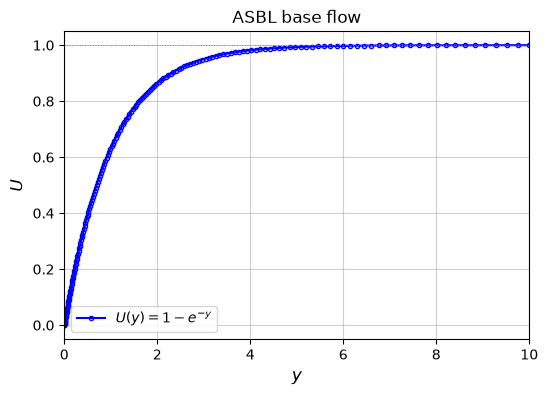

In [4]:
U   = 1.0 - np.exp(-y)
Upp = -np.exp(-y)           # U''(y)

fig = plt.figure()
plt.plot(y, U, 'b.-', label=r'$U(y)=1-e^{-y}$')
plt.axhline(1.0, color='gray', lw=0.7, ls=':')
plt.xlim([0, 10])
plt.xlabel(r'$y$')
plt.ylabel(r'$U$')
plt.legend()
plt.title('ASBL base flow')
plt.grid()
plt.show()

**Construct the Orr&ndash;Sommerfeld operators $A$ and $B$:**
Same structure as channel flow, plus the extra suction term $-\frac{1}{Re}(D^3-\alpha^2 D)$
derived above.

In [5]:
# A*vhat = omega*B*vhat
I = np.identity(N)
D2m = D2 - alpha**2*I                      # (D^2 - alpha^2 I)
D4m = D4 - 2*alpha**2*D2 + alpha**4*I      # (D^2 - alpha^2 I)^2

A = -D4m/Re + 1j*alpha*np.diag(U)@D2m - 1j*alpha*np.diag(Upp)
A += -(D3 - alpha**2*D1)/Re                # <-- the new suction term
B = 1j*D2m

Set the boundary conditions: no-slip/no-penetration at the wall, and decay of the disturbance
in the far field &mdash; both give $\hat v=\hat v'=0$:

$$
\hat v(y=0)=\hat v'(y=0)=0\,,\qquad \hat v(y=y_{\max})=\hat v'(y=y_{\max})=0\,,
$$

imposed by the same row-replacement trick as for channel flow (now using the mapped $D_1$ for the
Neumann rows).

In [6]:
# move the eigenvalues of the BC to Q
Q = -999j
# two homogeneous Dirichlet conditions (wall, far field)
A[0,:]  = Q*I[0,:];   B[0,:]  = I[0,:]
A[-1,:] = Q*I[-1,:];  B[-1,:] = I[-1,:]
# two homogeneous Neumann conditions (wall, far field)
A[1,:]  = Q*D1[0,:];  B[1,:]  = D1[0,:]
A[-2,:] = Q*D1[-1,:]; B[-2,:] = D1[-1,:]

**Solve the eigenvalue problem:** generalised eigenvalue problem, as before.

In [7]:
# compute eigenvalues and eigenvectors (A*vhat = omega*B*vhat)
omega, vv = scla.eig(A, B)
c = omega/alpha

# discard the huge (Q-related, boundary-condition) eigenvalues
valid = np.abs(omega) < 100
omega, c, vv = omega[valid], c[valid], vv[:, valid]

The eigenvalue (and eigenfunction) with the largest growth rate ($\mathrm{Im}(\omega)$, or
equivalently $\mathrm{Im}(c)$ since $\alpha>0$) is the leading Tollmien&ndash;Schlichting-type mode
&mdash; **with one caveat that has no analogue in channel flow.** Truncating the semi-infinite
domain discretizes the *continuous spectrum* associated with the free stream, which produces a
cluster of eigenvalues near $c_r=1$ (visible as a tight group in the spectrum plot below). These are
numerical representations of a genuine physical continuous spectrum, but they are not the
instability we are after, and at low growth rates they can sit right next to (or even above) the
true Tollmien&ndash;Schlichting eigenvalue in $\mathrm{Im}(\omega)$. We therefore restrict the search
for the leading mode to $c_r<0.9$, away from the free-stream cluster. As before, $u$ is obtained
from continuity, and the eigenfunctions are rescaled so the maximum of $u$ is real.

In [8]:
physical = c.real < 0.9   # exclude the discretised free-stream continuous spectrum (c_r~1)
i = np.where(physical)[0][np.argmax(omega[physical].imag)]
cmax = c[i]

v = vv[:,i]
u = -np.dot(D1, v)/(1j*alpha)   # continuity: i alpha u + Dv = 0

# rescale
j = np.argmax(abs(u))
w = u[j]
u /= w
v /= w

print('Leading eigenvalue c     = ', cmax)
print('Leading eigenvalue omega = ', cmax*alpha)

Leading eigenvalue c     =  (0.13219655741801+0.002102576866536603j)
Leading eigenvalue omega =  (0.0198294836127015+0.00031538652998049045j)


Plot the eigenvalue spectrum and the eigenfunctions for $u$ and $v$.

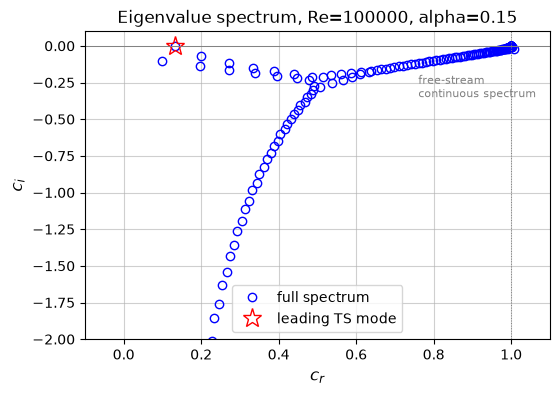

In [9]:
fig = plt.figure()
plt.plot(c.real, c.imag, 'ob', mfc='none', label='full spectrum')
plt.plot(cmax.real, cmax.imag, 'r*', ms=14, label='leading TS mode')
plt.axhline(0, color='gray', lw=0.7)
plt.axvline(1.0, color='gray', lw=0.7, ls=':')
plt.text(0.75, -0.35, ' free-stream\n continuous spectrum', fontsize=8, color='gray')
plt.grid()
plt.xlabel('$c_r$')
plt.ylabel('$c_i$')
plt.xlim(-0.1,1.1)
plt.ylim(-2,0.1)
plt.legend()
plt.title(f'Eigenvalue spectrum, Re={Re:.0f}, alpha={alpha}')
plt.show()

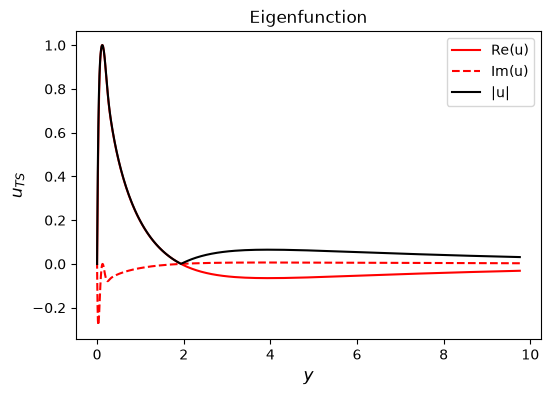

In [10]:
fig = plt.figure()
mask = y < 10
plt.plot(y[mask], u.real[mask], 'r', label='Re(u)')
plt.plot(y[mask], u.imag[mask], 'r--', label='Im(u)')
plt.plot(y[mask], abs(u[mask]), 'k-', label='|u|')
plt.legend(loc='best')
plt.xlabel(r'$y$')
plt.ylabel(r'$u_{TS}$')
plt.title('Eigenfunction')
plt.show()

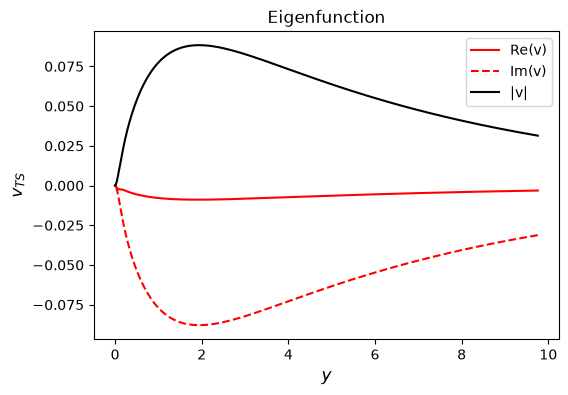

In [11]:
fig = plt.figure()
mask = y < 10
plt.plot(y[mask], v.real[mask], 'r', label='Re(v)')
plt.plot(y[mask], v.imag[mask], 'r--', label='Im(v)')
plt.plot(y[mask], abs(v[mask]), 'k-', label='|v|')
plt.xlabel(r'$y$')
plt.ylabel(r'$v_{TS}$')
plt.legend(loc='best')
plt.title('Eigenfunction')
plt.show()

## Validation against published results

Two independent checks against the literature:

1. **With** the suction term, at the published critical point $Re_c=54\,378.62$,
   $\alpha_c=0.15546$ (Yalcin, T&uuml;rka&ccedil; &amp; Oberlack, *Phys. Fluids* 2021, refining
   Fransson &amp; Alfredsson 2003), the leading eigenvalue should have $\omega_i\approx0$ and
   $\omega_r\approx0.023297$.
2. **Without** the suction term (i.e. solving the *unmodified* Orr&ndash;Sommerfeld equation with
   the ASBL profile substituted in, as Hughes &amp; Reid did in 1965), the neutral point should
   shift to $Re_c\approx47\,047$ at $\alpha\approx0.163$.

Both are reproduced below using a compact version of the solver above, wrapped in a function so it
can be called repeatedly.

In [12]:
def solve_ASBL(Re, alpha, N, y_i, y_max, suction_term=True):
    # leading eigenvalue omega of the (modified) ASBL Orr-Sommerfeld problem
    # -- clustered algebraic map, exact D1,D2,D3 metric terms, D4 = D2 @ D2
    x, DM = chebdif(N, 3)
    Dx, Dx2, Dx3 = DM[0], DM[1], DM[2]
    b = 1.0 + 2.0*y_i/y_max
    y = y_i*(1+x)/(b-x)
    J   = y_i*(b+1)/(b-x)**2
    Jp  = 2.0*J/(b-x)
    Jpp = 6.0*J/(b-x)**2
    D1 = np.diag(1.0/J)                     @ Dx
    D2 = np.diag(1.0/J**2)                  @ Dx2 - np.diag(Jp/J**3)       @ Dx
    D3 = np.diag(1.0/J**3)                  @ Dx3 - np.diag(3*Jp/J**4)     @ Dx2 \
         + np.diag(3*Jp**2/J**5 - Jpp/J**4) @ Dx
    D4 = D2 @ D2

    U, Upp = 1.0-np.exp(-y), -np.exp(-y)
    I = np.identity(N)
    D2m = D2 - alpha**2*I
    D4m = D4 - 2*alpha**2*D2 + alpha**4*I

    A = -D4m/Re + 1j*alpha*np.diag(U)@D2m - 1j*alpha*np.diag(Upp)
    if suction_term:
        A += -(D3 - alpha**2*D1)/Re
    B = 1j*D2m

    Q = -999j
    A[0,:]=Q*I[0,:];   B[0,:]=I[0,:]
    A[-1,:]=Q*I[-1,:]; B[-1,:]=I[-1,:]
    A[1,:]=Q*D1[0,:];  B[1,:]=D1[0,:]
    A[-2,:]=Q*D1[-1,:];B[-2,:]=D1[-1,:]

    omega, _ = scla.eig(A, B)
    c = omega/alpha
    # drop BC artifacts and the discretised free-stream continuous spectrum (c_r~1)
    physical = (np.abs(omega) < 100) & (c.real < 0.9)
    omega = omega[physical]
    return omega[np.argmax(omega.imag)]

om1 = solve_ASBL(54378.62, 0.15546, 150, 3.0, 40.0, suction_term=True)
print(f'With suction term,    Re=54378.62, alpha=0.15546:  omega = {om1:.6f}   (lit: 0.023297 + 0.000000j)')

om2 = solve_ASBL(47047, 0.163, 150, 3.0, 40.0, suction_term=False)
print(f'Without suction term, Re=47047,    alpha=0.163   :  omega = {om2:.6f}   (Hughes & Reid 1965: c_i approx 0)')

With suction term,    Re=54378.62, alpha=0.15546:  omega = 0.023296+0.000000j   (lit: 0.023297 + 0.000000j)
Without suction term, Re=47047,    alpha=0.163   :  omega = 0.025420-0.000001j   (Hughes & Reid 1965: c_i approx 0)


## Does the clustered mapping help?

The first version of this notebook used a plain linear map, $y=\tfrac{y_{\max}}2(1-x)$, relying
only on Chebyshev's own endpoint clustering. Let's put both maps head to head, at fixed physical
parameters (the published critical point), varying only $N$. The linear-map solver below is exactly
the original implementation, kept unchanged for a fair comparison.

In [13]:
def solve_ASBL_linear(Re, alpha, N, y_max, suction_term=True):
    # original linear-map solver, for comparison
    x, DM = chebdif(N, 4)
    D1x, D2x, D3x, D4x = DM[0], DM[1], DM[2], DM[3]
    Jc = 2.0/y_max
    D1, D2, D3, D4 = -Jc*D1x, Jc**2*D2x, -Jc**3*D3x, Jc**4*D4x
    y = y_max*(1-x)/2.0

    U, Upp = 1.0-np.exp(-y), -np.exp(-y)
    I = np.identity(N)
    D2m = D2 - alpha**2*I
    D4m = D4 - 2*alpha**2*D2 + alpha**4*I
    A = -D4m/Re + 1j*alpha*np.diag(U)@D2m - 1j*alpha*np.diag(Upp)
    if suction_term:
        A += -(D3 - alpha**2*D1)/Re
    B = 1j*D2m

    Q = -999j
    A[0,:]=Q*I[0,:];   B[0,:]=I[0,:]
    A[-1,:]=Q*I[-1,:]; B[-1,:]=I[-1,:]
    A[1,:]=Q*D1[0,:];  B[1,:]=D1[0,:]
    A[-2,:]=Q*D1[-1,:];B[-2,:]=D1[-1,:]

    omega, _ = scla.eig(A, B)
    c = omega/alpha
    physical = (np.abs(omega) < 100) & (c.real < 0.9)
    omega = omega[physical]
    return omega[np.argmax(omega.imag)]

Re_c, alpha_c = 54378.62, 0.15546
print(f'{"N":>5} {"linear map":>24} {"clustered map":>24}')
print(f'{"":>5} {"(y_max=40)":>24} {"(y_i=3, y_max=40)":>24}')
for Ntest in [40, 60, 80, 100, 150, 200, 250, 350,500]:
    om_lin = solve_ASBL_linear(Re_c, alpha_c, Ntest, 40.0)
    om_map = solve_ASBL(Re_c, alpha_c, Ntest, 3.0, 40.0)
    print(f'{Ntest:5d} {om_lin.real:10.7f}{om_lin.imag:+.7f}j   {om_map.real:10.7f}{om_map.imag:+.7f}j')

print()
print('literature value: omega = 0.023297 + 0.000000j')

    N               linear map            clustered map
                    (y_max=40)        (y_i=3, y_max=40)
   40  0.1280582-0.0001378j    0.0232950+0.0000145j
   60  0.0239691+0.0003431j    0.0232961+0.0000004j
   80  0.0233672+0.0000567j    0.0232961+0.0000002j
  100  0.0234428+0.0001022j    0.0232960+0.0000001j
  150  0.0232933+0.0000028j    0.0232959+0.0000000j
  200  0.0232959-0.0000001j    0.0232959+0.0000000j
  250  0.0232958-0.0000000j    0.0232958+0.0000000j
  350  0.0232958-0.0000000j    0.0232958-0.0000000j
  500  0.0232958-0.0000000j    0.0232944+0.0000002j

literature value: omega = 0.023297 + 0.000000j


**Yes, substantially.** The clustered map is already converged to 5&ndash;6 significant
digits by $N\approx60$&ndash;80, whereas the linear map needs $N\approx200$&ndash;250 for the same
accuracy &mdash; at $N=40$ the linear map is still off by a factor of several, while the clustered map
is already correct to 3 significant figures. This is exactly what the mapping is designed to fix:
the physics (the mean-flow curvature, the near-wall structure of the eigenfunction) all happens
within a few $\delta^*$ of the wall, but a plain linear map spends about half of its Chebyshev
points resolving the featureless free-stream out near $y_{\max}$, while the clustered map spends
them where the dynamics actually live. Because the eigenvalue problem costs $O(N^3)$ to solve, the
practical payoff is an order of magnitude in run time for the same accuracy, which matters most for
the neutral-curve scan below (many hundreds of solves). From here on the notebook uses the clustered
map with $N=150$, $y_i=3$, $y_{\max}=40$ throughout &mdash; already converged well beyond the digits
that matter, as the next section confirms directly.

## Numerical convergence

With the clustered map, check sensitivity to all three numerical parameters: $N$, the clustering
parameter $y_i$, and the truncation length $y_{\max}$.

In [14]:
print('Convergence with N (y_i=3, y_max=40 fixed):')
for Ntest in [60,80,100,130,160,200]:
    om = solve_ASBL(54378.62, 0.15546, Ntest, 3.0, 40.0)
    print(f'  N={Ntest:4d}    omega = {om:.7f}')

print()
print('Convergence with y_i (N=150, y_max=40 fixed):')
for yitest in [1.0,1.5,2.0,3.0,4.0,6.0]:
    om = solve_ASBL(54378.62, 0.15546, 150, yitest, 40.0)
    print(f'  y_i={yitest:4.1f}   omega = {om:.7f}')

print()
print('Convergence with y_max (N=150, y_i=3 fixed):')
for ymtest in [20,25,30,40,60,80]:
    om = solve_ASBL(54378.62, 0.15546, 150, 3.0, ymtest)
    print(f'  y_max={ymtest:5.1f}  omega = {om:.7f}')

Convergence with N (y_i=3, y_max=40 fixed):
  N=  60    omega = 0.0232961+0.0000004j
  N=  80    omega = 0.0232961+0.0000002j
  N= 100    omega = 0.0232960+0.0000001j
  N= 130    omega = 0.0232959+0.0000001j
  N= 160    omega = 0.0232959+0.0000000j
  N= 200    omega = 0.0232959+0.0000000j

Convergence with y_i (N=150, y_max=40 fixed):
  y_i= 1.0   omega = 0.0232964+0.0000005j
  y_i= 1.5   omega = 0.0232961+0.0000002j
  y_i= 2.0   omega = 0.0232960+0.0000001j
  y_i= 3.0   omega = 0.0232959+0.0000000j
  y_i= 4.0   omega = 0.0232959+0.0000000j
  y_i= 6.0   omega = 0.0232958+0.0000000j

Convergence with y_max (N=150, y_i=3 fixed):
  y_max= 20.0  omega = 0.0233321-0.0000043j
  y_max= 25.0  omega = 0.0233036-0.0000007j
  y_max= 30.0  omega = 0.0232975-0.0000000j
  y_max= 40.0  omega = 0.0232959+0.0000000j
  y_max= 60.0  omega = 0.0232958+0.0000000j
  y_max= 80.0  omega = 0.0232957+0.0000000j


## Neutral stability curve for the ASBL

As for channel flow, compute the contours of $\max(\omega_i)$ over a grid of $(Re,\alpha)$; the
$\max(\omega_i)=0$ isoline is the **neutral stability curve**. The clustered map's much faster
convergence (previous section) lets us afford a finer $(Re,\alpha)$ mesh than the linear-map version
for about the same total run time. Create the mesh:

In [15]:
N_Re = 36
N_alpha = 36
RE, ALPHA = np.meshgrid(np.linspace(20000, 200000, N_Re), np.linspace(0.05, 0.28, N_alpha))

Compute $\max(\omega_i)$ for every $(Re,\alpha)$ in the mesh, using $N=100$ (already
converged to 5+ digits at the critical point &mdash; see above &mdash; and about $3\times$ faster per
solve than the $N=150$ used for the single-case demo).

In [16]:
g = np.zeros((N_alpha, N_Re))
for ii in range(N_Re):
    for jj in range(N_alpha):
        g[jj,ii] = solve_ASBL(RE[jj,ii], ALPHA[jj,ii], 100, 3.0, 40.0).imag

Plot the contours of $\max(\omega_i)$, with a solid contour line at $\max(\omega_i)=0$, and
compare to the refined critical point of Yalcin, T&uuml;rka&ccedil; &amp; Oberlack (2021)
/ Fransson &amp; Alfredsson (2003).

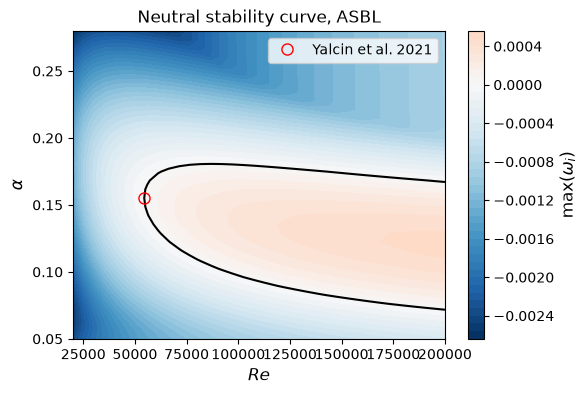

In [17]:
fig = plt.figure()
CS = plt.contourf(RE[0,:], ALPHA[:,0], g, levels=40, cmap='RdBu_r',
                   vmin=-np.max(np.abs(g)), vmax=np.max(np.abs(g)))
plt.colorbar(label=r'$\max(\omega_i)$')
CS1 = plt.contour(RE[0,:], ALPHA[:,0], g, levels=[0], colors='k')
plt.xlabel(r'$Re$')
plt.ylabel(r'$\alpha$')
plt.plot(54378.62, 0.15546, 'ro', ms=8, label='Yalcin et al. 2021')
plt.legend()
plt.title('Neutral stability curve, ASBL')
plt.show()